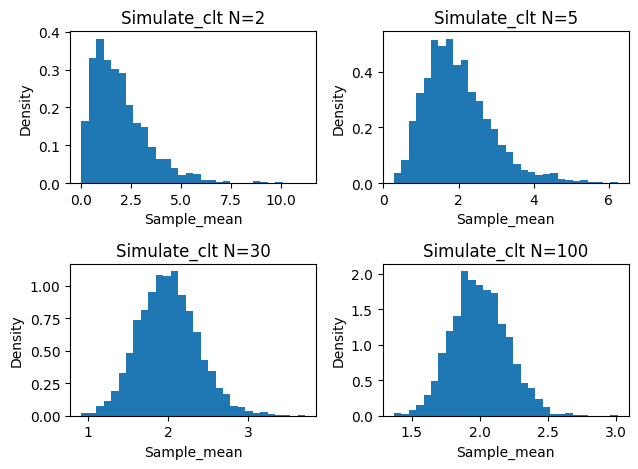

In [10]:
import numpy as np
import matplotlib.pyplot as plt
def simulate_clt(lamda:float=0.5,K:int=2000,N_list:list=[2,5,30,100]):
    scale=1/lamda
    fig,axes=plt.subplots(2,2)
    axes=axes.flatten()
    for i,N in enumerate(N_list):
        sample=np.random.exponential(scale,size=(K,N))
        sample_mean=np.mean(sample,axis=1)
        axes[i].hist(sample_mean,bins=30,density=True,alpha=1)
        axes[i].set_title(f"Simulate_clt N={N}")
        axes[i].set_xlabel("Sample_mean")
        axes[i].set_ylabel("Density")
    plt.tight_layout()
    plt.show()
simulate_clt(0.5,2000,[2,5,30,100])

In [13]:
import math
import numpy as np
def ab_test_proportions(x_a: int,n_a: int,x_b: int,n_b: int,alpha:float=0.5):
        p_a=x_a/n_a
        p_b=x_b/n_b
        p_pool=(x_a+x_b)/(n_a+n_b)
        SE=np.sqrt(p_pool*(1-p_pool)*(1/n_a+1/n_b))
        Z=(p_b-p_a)/SE
        phi=0.5*[(1+math.erf(np.abs(Z)))/math.sqrt(2)]
        p_value=2*(1-phi)
        diff=p_b-p_a
        ci_low=diff-1.96 * SE
        ci_high = diff + 1.96 * SE
        if p_value < alpha:
            conclusion = "Bác bỏ H0: Thuật toán B tạo ra sự khác biệt có nghĩa thống kê"
        else:
            conclusion = "Chưa đủ bằng chứng để bác bỏ H0"
        return p_a, p_b, Z, p_value, (ci_low, ci_high), conclusion

Bản chất toán học cốt lõi của Bài tập 2 (Mô phỏng CLT & Đánh giá A/B Testing) gói gọn trong việc biến sự hỗn loạn của từng cá nhân thành quy luật chắc chắn của đám đông, được xây dựng trên 3 trụ cột nối tiếp nhau:   1. Cầu nối từ Rời rạc/Lệch sang Phân phối Chuẩn (Định lý Giới hạn Trung tâm - CLT)Vấn đề thực tế: Dữ liệu gốc trong thực tế hiếm khi tuân theo phân phối chuẩn. Ví dụ: thời gian chờ có phân phối mũ lệch phải cực mạnh, hoặc hành vi click chuột của 1 người dùng chỉ là biến ngẫu nhiên Bernoulli rời rạc (chỉ nhận giá trị $0$ hoặc $1$, hoàn toàn không phải hình chuông).   Phép màu của CLT: Dù phân phối gốc có méo mó hay rời rạc đến đâu (miễn là có kỳ vọng $\mu$ và phương sai $\sigma^2$ hữu hạn), khi bạn lấy trung bình cộng của một mẫu đủ lớn ($N$ lớn), phân phối của các giá trị trung bình mẫu đó sẽ luôn tự động hội tụ về hình chuông đối xứng của Phân phối chuẩn Gauss $\mathcal{N}(\mu, \sigma^2/N)$.   Ý nghĩa của mẫu số $N$ trong $\sigma^2/N$: Kích thước mẫu $N$ càng lớn thì phương sai của trung bình mẫu càng nhỏ (quả chuông trong histogram của bạn càng cao và hẹp lại quanh giá trị trung bình thực), tức là ước lượng từ mẫu càng chính xác.   2. Bản chất của Kiểm định A/B Testing: Tỉ số "Tín hiệu trên Nhiễu" (Signal-to-Noise Ratio)Khi so sánh tỷ lệ click (CTR) $\hat{p}_B$ và $\hat{p}_A$, việc thấy $\hat{p}_B > \hat{p}_A$ chưa đủ để kết luận thuật toán B tốt hơn vì sự chênh lệch đó có thể chỉ do ngẫu nhiên may rủi khi rút mẫu. Để phân biệt thực lực và ăn may, toán học dùng thống kê $Z$:   $$Z = \frac{\hat{p}_B - \hat{p}_A}{SE_{pool}}$$   Tử số ($\hat{p}_B - \hat{p}_A$) là "Tín hiệu" (Signal): Mức chênh lệch thực tế quan sát được giữa hai thuật toán.   Mẫu số ($SE_{pool}$) là "Độ nhiễu" (Noise): Độ dao động ngẫu nhiên tự nhiên của hiệu hai tỷ lệ nếu giả định cả hai thuật toán thực chất giống hệt nhau ($H_0: p_B - p_A = 0$). Đó là lý do ta phải gộp chung hai mẫu lại để tính một tỷ lệ gốc duy nhất $\hat{p}_{pool} = \frac{x_A + x_B}{n_A + n_B}$ dưới giả thuyết $H_0$.   Giá trị $Z$: Cho biết khoảng cách giữa thuật toán B và A lớn gấp bao nhiêu lần "độ lệch chuẩn nhiễu". Nhờ có CLT ở trụ cột 1, tỷ lệ $\hat{p}_A$ và $\hat{p}_B$ xấp xỉ phân phối chuẩn, nên hiệu của chúng chia cho sai số chuẩn tạo thành biến $Z$ tuân theo phân phối chuẩn tắc $\mathcal{N}(0, 1)$.   3. Bản chất của p-value và Mức ý nghĩa $\alpha$: Chứng minh phản chứng bằng xác suấtThống kê suy luận sử dụng tư duy tương tự chứng minh phản chứng trong toán học:Bước 1 (Giả sử điều ngược lại): Tạm tin rằng $H_0$ đúng — tức là thuật toán B chẳng tạo ra khác biệt gì so với A ($p_B - p_A = 0$).   Bước 2 (Tính xác suất xảy ra hiện tượng cực đoan - p-value): Công thức $\text{p-value} = 2 \cdot (1 - \Phi(\vert{}Z\vert{}))$ tính tổng diện tích hai phần đuôi ngoài cùng của hình chuông chuẩn tắc. Con số này trả lời câu hỏi: "Nếu hai thuật toán thực sự y hệt nhau ($H_0$ đúng), thì xác suất để sự ngẫu nhiên may rủi tự tạo ra được độ chênh lệch lớn bằng hoặc lớn hơn mức $\vert{}Z\vert{}$ đang thấy là bao nhiêu?".   Bước 3 (Ra quyết định với ngưỡng $\alpha = 0.05$): Nếu xác suất "ăn may" đó quá nhỏ ($\text{p-value} < 0.05$, tức cơ hội ngẫu nhiên xảy ra chưa tới $5\%$), ta kết luận giả định ban đầu ($H_0$) là vô lý và bác bỏ $H_0$, công nhận thuật toán B tạo ra sự khác biệt có ý nghĩa thống kê. Ngược lại, nếu $\text{p-value} \ge 0.05$, mức chênh lệch hiện tại hoàn toàn có thể giải thích bởi biến động ngẫu nhiên, nên ta chưa đủ bằng chứng để bác bỏ $H_0$.   Tóm lại: CLT cho phép bạn dùng hình chuông Gauss cho mọi loại dữ liệu khi mẫu lớn $\rightarrow$ Điểm $Z$ chuẩn hóa độ lệch giữa 2 mô hình lên hình chuông đó $\rightarrow$ p-value đo diện tích đuôi chuông để quyết định xem mô hình AI mới thực sự tốt hơn hay chỉ là ngẫu nhiên.